In [51]:
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix

In [2]:
data=pd.read_csv('Bank Customer Churn Prediction.csv')
data.head()

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
data.shape

(10000, 12)

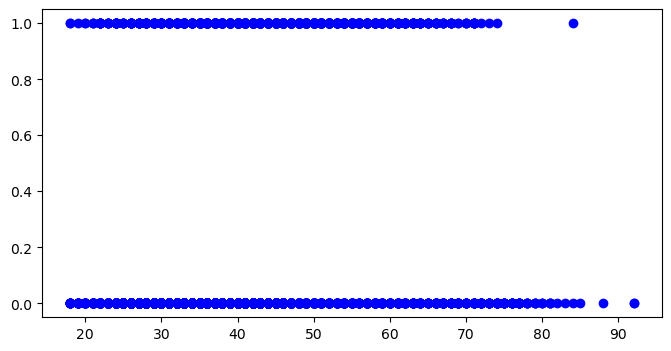

In [4]:
plt.figure(figsize=(8, 4))
plt.scatter(data['age'], data['churn'], color='b')

plt.show()

In [5]:
data.isnull().sum()

customer_id         0
credit_score        0
country             0
gender              0
age                 0
tenure              0
balance             0
products_number     0
credit_card         0
active_member       0
estimated_salary    0
churn               0
dtype: int64

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       10000 non-null  int64  
 1   credit_score      10000 non-null  int64  
 2   country           10000 non-null  object 
 3   gender            10000 non-null  object 
 4   age               10000 non-null  int64  
 5   tenure            10000 non-null  int64  
 6   balance           10000 non-null  float64
 7   products_number   10000 non-null  int64  
 8   credit_card       10000 non-null  int64  
 9   active_member     10000 non-null  int64  
 10  estimated_salary  10000 non-null  float64
 11  churn             10000 non-null  int64  
dtypes: float64(2), int64(8), object(2)
memory usage: 937.6+ KB


In [7]:
data.describe()

,customer_id,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
count,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [8]:
data=data.drop(['customer_id'], axis=1)
data.head()

,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [9]:
x=data.drop(['churn' ], axis=1)

y=data['churn']

In [10]:
x_train,x_test, y_train,y_test = train_test_split(x,y,test_size=0.2, random_state=42)

In [11]:
label_encoder = LabelEncoder()

for col in x_train.select_dtypes(include=['object']).columns:
    x_train[col]=label_encoder.fit_transform(x_train[col])
    x_test[col]=label_encoder.fit_transform(x_test[col])

x_train.head()

,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary
9254,686,0,1,32,6,0.00,2,1,1,179093.26
1561,632,1,1,42,4,119624.60,2,1,1,195978.86
1670,559,2,1,24,3,114739.92,1,1,0,85891.02
6087,561,0,0,27,9,135637.00,1,1,0,153080.40
6669,517,0,1,56,9,142147.32,1,0,0,39488.04


In [12]:
x_train_scaled = x_train.copy()
x_test_scaled = x_test.copy()

In [13]:
MMS = MinMaxScaler()

col_to_scale = ['credit_score', 'age', 'tenure', 'balance', 'estimated_salary']

for col in col_to_scale:
    x_train_scaled[col] = MMS.fit_transform(x_train[[col]])
    x_test_scaled[col] = MMS.fit_transform(x_test[[col]])

x_train_scaled.head()

,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary
9254,0.672,0,1,0.189189,0.6,0.000000,2,1,1,0.895550
1561,0.564,1,1,0.324324,0.4,0.476786,2,1,1,0.980029
1670,0.418,2,1,0.081081,0.3,0.457317,1,1,0,0.429261
6087,0.422,0,0,0.121622,0.9,0.540606,1,1,0,0.765408
6669,0.334,0,1,0.513514,0.9,0.566554,1,0,0,0.197107


## Logistic Regression Model + Ridge Regularization (L2)


In [14]:
model_L2= LogisticRegression(penalty='l2', C=0.01)
model_L2.fit(x_train_scaled, y_train)

LogisticRegression(C=0.01)

In [15]:
model_L2.coef_

array([[-0.10966702,  0.10503047, -0.39885131,  1.05300892, -0.06362987,
         0.47386053, -0.12402793, -0.02251874, -0.61642628,  0.03713698]])

In [16]:
y_predicted_l2 =model_L2.predict(x_test_scaled)
y_predicted_l2

array([0, 0, 0, ..., 0, 0, 0], dtype=int64)

In [17]:
def score( y_pred, y_true):
    print(f'Accuracy : {accuracy_score(y_test, y_pred)}')
    print(f'recall : {recall_score(y_true,y_pred)}')
    print(f'presecion : {precision_score(y_test, y_pred)}')
    print(f'F1Score : {f1_score(y_test, y_pred)}')
    print(f'Conf_Matrix :\n {confusion_matrix(y_test, y_pred)}')


In [18]:
score(y_test,y_predicted_l2)
score

Accuracy : 1.0
recall : 0.0
presecion : 1.0
F1Score : 1.0
Conf_Matrix :
 [[1607    0]
 [   0  393]]


C:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


<function __main__.score(y_pred, y_true)>

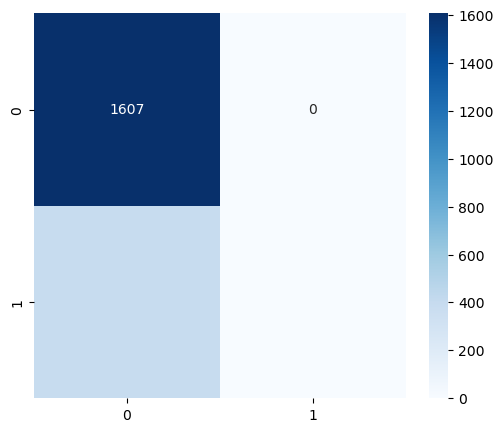

In [19]:
cm=confusion_matrix(y_test, y_predicted_l2)

plt.figure(figsize=(6,5))
sns.heatmap(cm, cmap='Blues', annot=True, fmt="g")
plt.show()

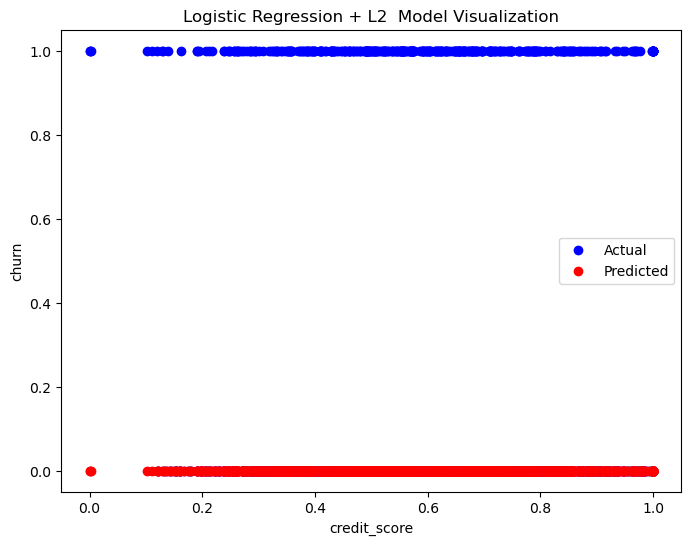

In [23]:
plt.figure(figsize=(8, 6))
plt.scatter(x_test_scaled['credit_score'], y_test, color='blue', label='Actual')

plt.scatter(x_test_scaled['credit_score'], y_predicted_l2, color='red', label='Predicted')

plt.xlabel('credit_score')
plt.ylabel('churn')
plt.title('Logistic Regression + L2  Model Visualization')
plt.legend()
plt.show()

## Logistic Regression Model + Lasso Regularization (L1)


In [24]:
model_L1= LogisticRegression(penalty='l1', C=0.01, solver='liblinear')
model_L1.fit(x_train_scaled, y_train)

LogisticRegression(C=0.01, penalty='l1', solver='liblinear')

In [25]:
model_L1.coef_

array([[ 0.        ,  0.        , -0.372678  ,  0.16018915,  0.        ,
         0.        , -0.33783721,  0.        , -0.60165841,  0.        ]])

In [26]:
y_predicted_l1 =model_L1.predict(x_test_scaled)

def score( y_pred, y_true):
    print(f'Accuracy : {accuracy_score(y_test, y_pred)}')
    print(f'recall : {recall_score(y_true,y_pred)}')
    print(f'presecion : {precision_score(y_test, y_pred)}')
    print(f'F1Score : {f1_score(y_test, y_pred)}')
    print(f'Conf_Matrix :\n {confusion_matrix(y_test, y_pred)}')

In [27]:
score(y_test,y_predicted_l1)
score

Accuracy : 1.0
recall : 0.0
presecion : 1.0
F1Score : 1.0
Conf_Matrix :
 [[1607    0]
 [   0  393]]


C:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


<function __main__.score(y_pred, y_true)>

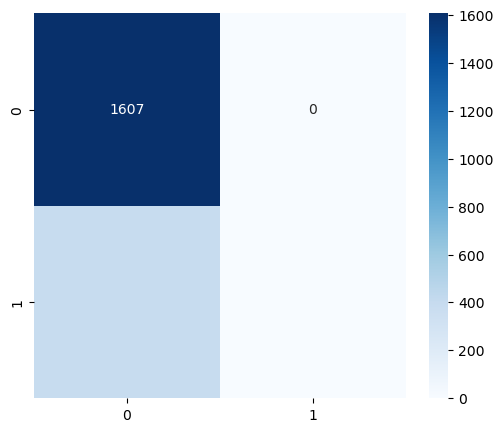

In [28]:
cm=confusion_matrix(y_test, y_predicted_l1)

plt.figure(figsize=(6,5))
sns.heatmap(cm, cmap='Blues', annot=True, fmt="g")
plt.show()

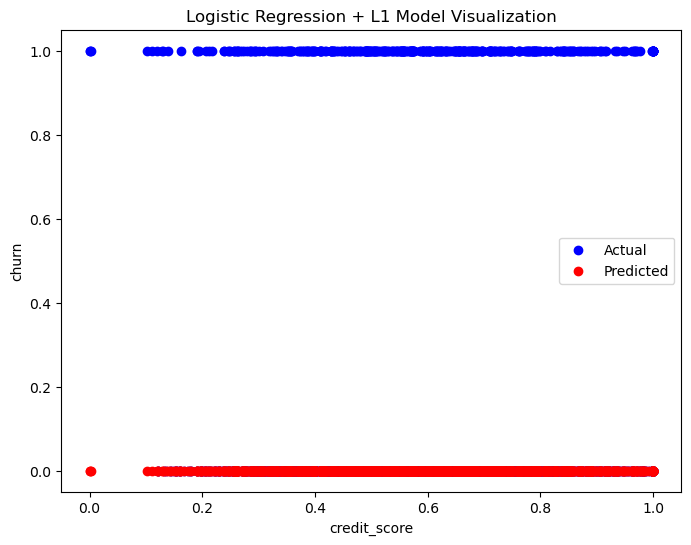

In [30]:
plt.figure(figsize=(8, 6))
plt.scatter(x_test_scaled['credit_score'], y_test, color='blue', label='Actual')

plt.scatter(x_test_scaled['credit_score'], y_predicted_l1, color='red', label='Predicted')

plt.xlabel('credit_score')
plt.ylabel('churn')
plt.title('Logistic Regression + L1 Model Visualization')
plt.legend()
plt.show()

## Model Decision Tree

In [47]:
model_DT = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=0)
model_DT.fit(x_train_scaled, y_train)

y_pred = model_DT.predict(x_test_scaled)
y_pred

array([0, 0, 0, ..., 1, 0, 0], dtype=int64)

In [48]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, digits=4))

              precision    recall  f1-score   support

           0     0.8726    0.9502    0.9097      1607
           1     0.6800    0.4326    0.5288       393

    accuracy                         0.8485      2000
   macro avg     0.7763    0.6914    0.7193      2000
weighted avg     0.8347    0.8485    0.8349      2000



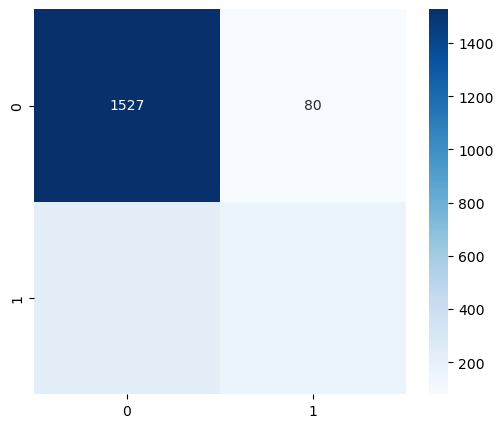

In [50]:
cm=confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, cmap='Blues', annot=True, fmt="g")
plt.show()

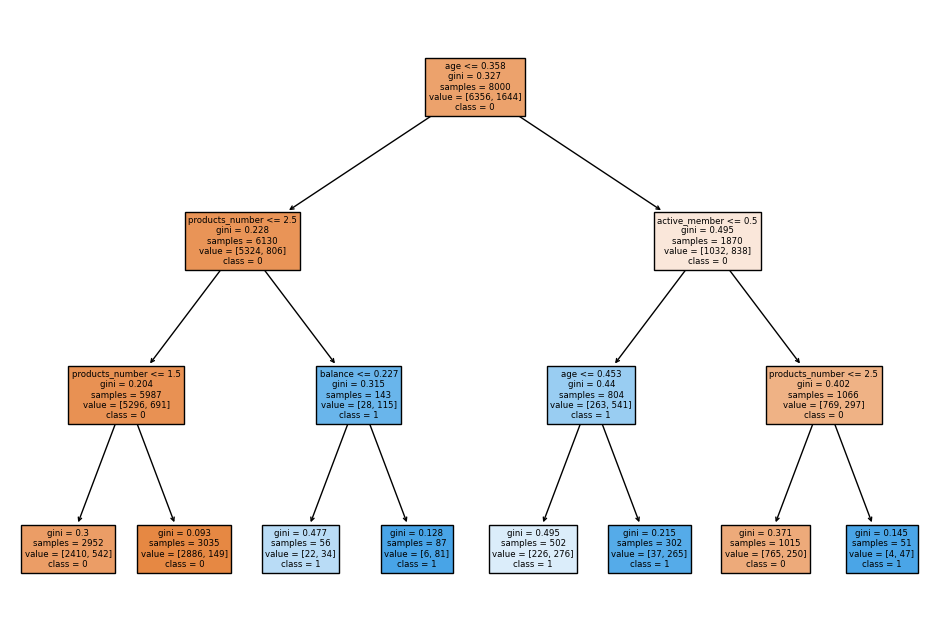

In [61]:
feature_names = ['credit_score','country','gender','age','tenure','balance','products_number','credit_card','active_member','estimated_salary']

plt.figure(figsize=(12, 8))
plot_tree(
    model_DT, 
    feature_names=feature_names, 
    class_names=model_DT.classes_.astype(str), 
    filled=True
)
plt.show()
plt.show()

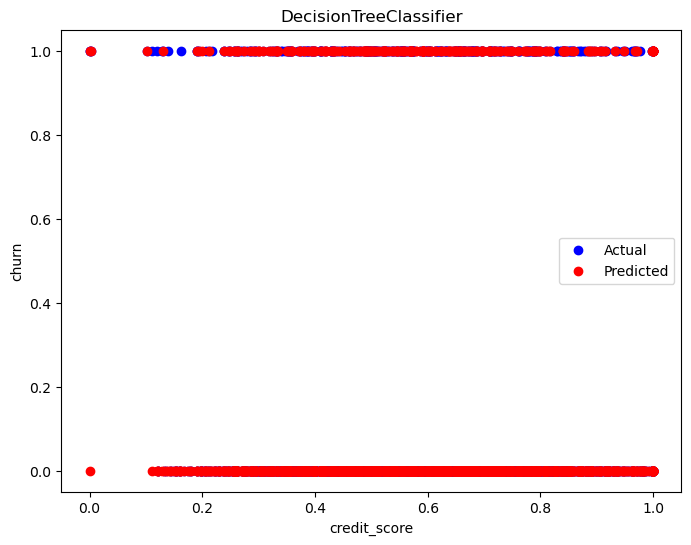

In [49]:
plt.figure(figsize=(8, 6))
plt.scatter(x_test_scaled['credit_score'], y_test, color='blue', label='Actual')

plt.scatter(x_test_scaled['credit_score'], y_pred, color='red', label='Predicted')

plt.xlabel('credit_score')
plt.ylabel('churn')
plt.title('DecisionTreeClassifier')
plt.legend()
plt.show()